# Crop Yield Prediction using the KDD Process
**Task:** Regression – predict crop yield (`hg/ha_yield`) from country, crop, year, rainfall, pesticides and temperature.

**Rules followed:** k-NN and Random Forest are written **from scratch using maths (NumPy only)**. Everything else (loading, plotting, etc.) uses normal libraries.

## The KDD Process (Knowledge Discovery in Databases)

| Step | Name | What we do here |
|---|---|---|
| 1 | **Selection** | Load the 3 files and pick the useful data |
| 2 | **Pre-processing** | Clean: missing values, duplicates, outliers |
| 3 | **Transformation** | Encode text → numbers, split train/test, scale |
| 4 | **Data Mining** | Build k-NN and Random Forest |
| 5 | **Interpretation / Evaluation** | MAE, RMSE, R², graphs, feature importance → knowledge |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Change FOLDER to "." if the csv files are next to this notebook
FOLDER = "/content/drive/MyDrive"
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    FOLDER = "."

Mounted at /content/drive


---
# STEP 1 – Selection
**Goal:** choose the data relevant to the problem.

We have 3 files: `yield_df.csv` (yield + temperature), `rainfall.csv`, `pesticides.csv`.
We select the needed columns from each and join them on **Country (Area) + Year**.

In [2]:
yield_raw = pd.read_csv(f"{FOLDER}/yield_df.csv")
rain_raw  = pd.read_csv(f"{FOLDER}/rainfall.csv")
pest_raw  = pd.read_csv(f"{FOLDER}/pesticides.csv")
print("yield     :", yield_raw.shape)
print("rainfall  :", rain_raw.shape)
print("pesticides:", pest_raw.shape)

# select useful columns from each file
yield_df = yield_raw[["Area", "Item", "Year", "hg/ha_yield", "avg_temp"]].copy()

rain = rain_raw.rename(columns=lambda c: c.strip())[["Area", "Year", "average_rain_fall_mm_per_year"]].copy()
rain["average_rain_fall_mm_per_year"] = pd.to_numeric(rain["average_rain_fall_mm_per_year"], errors="coerce")

pest = pest_raw[pest_raw["Item"] == "Pesticides (total)"][["Area", "Year", "Value"]].copy()
pest = pest.rename(columns={"Value": "pesticides_tonnes"})

for t in (yield_df, rain, pest):
    t["Area"] = t["Area"].str.strip()

# join the three tables on Country + Year
df = (yield_df.merge(rain, on=["Area", "Year"])
              .merge(pest, on=["Area", "Year"]))
print("\nSelected data shape:", df.shape)
df.head()

yield     : (28242, 8)
rainfall  : (6727, 3)
pesticides: (4349, 7)

Selected data shape: (28242, 7)


,Area,Item,Year,hg/ha_yield,avg_temp,average_rain_fall_mm_per_year,pesticides_tonnes
0,Albania,Maize,1990,36613,16.37,1485.0,121.0
1,Albania,Potatoes,1990,66667,16.37,1485.0,121.0
2,Albania,"Rice, paddy",1990,23333,16.37,1485.0,121.0
3,Albania,Sorghum,1990,12500,16.37,1485.0,121.0
4,Albania,Soybeans,1990,7000,16.37,1485.0,121.0


In [3]:
print(df.dtypes)
df.describe().round(2)

Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
avg_temp                         float64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
dtype: object


,Year,hg/ha_yield,avg_temp,average_rain_fall_mm_per_year,pesticides_tonnes
count,28242.00,28242.00,28242.00,28242.00,28242.00
mean,2001.54,77053.33,20.54,1149.06,37076.91
std,7.05,84956.61,6.31,709.81,59958.78
min,1990.00,50.00,1.30,51.00,0.04
25%,1995.00,19919.25,16.70,593.00,1702.00
50%,2001.00,38295.00,21.51,1083.00,17529.44
75%,2008.00,104676.75,26.00,1668.00,48687.88
max,2013.00,501412.00,30.65,3240.00,367778.00


---
# STEP 2 – Pre-processing
**Goal:** clean the data so it is reliable.

1. Remove missing values
2. Remove duplicate rows
3. Check for outliers (IQR rule on the target)

In [4]:
print("Missing values:\n", df.isnull().sum(), "\n")
n0 = len(df)
df = df.dropna()
n1 = len(df)
df = df.drop_duplicates()
n2 = len(df)
print(f"Rows at start: {n0} | removed missing: {n0-n1} | removed duplicates: {n1-n2} | kept: {n2}")

# Outlier check with IQR:  outside [Q1 - 1.5*IQR , Q3 + 1.5*IQR]
q1, q3 = df["hg/ha_yield"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((df["hg/ha_yield"] < low) | (df["hg/ha_yield"] > high)).sum()
print(f"Possible outliers in yield: {n_out} ({n_out/len(df):.1%}) -> kept (they are real high-yield crops like potato)")

df["yield_t_ha"] = df["hg/ha_yield"] / 10000     # tonnes/ha, easier to read in graphs

Missing values:
 Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
avg_temp                         0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
dtype: int64 

Rows at start: 28242 | removed missing: 0 | removed duplicates: 2310 | kept: 25932
Possible outliers in yield: 1918 (7.4%) -> kept (they are real high-yield crops like potato)


### Quick exploration (EDA)
A few graphs to understand the data before modelling.

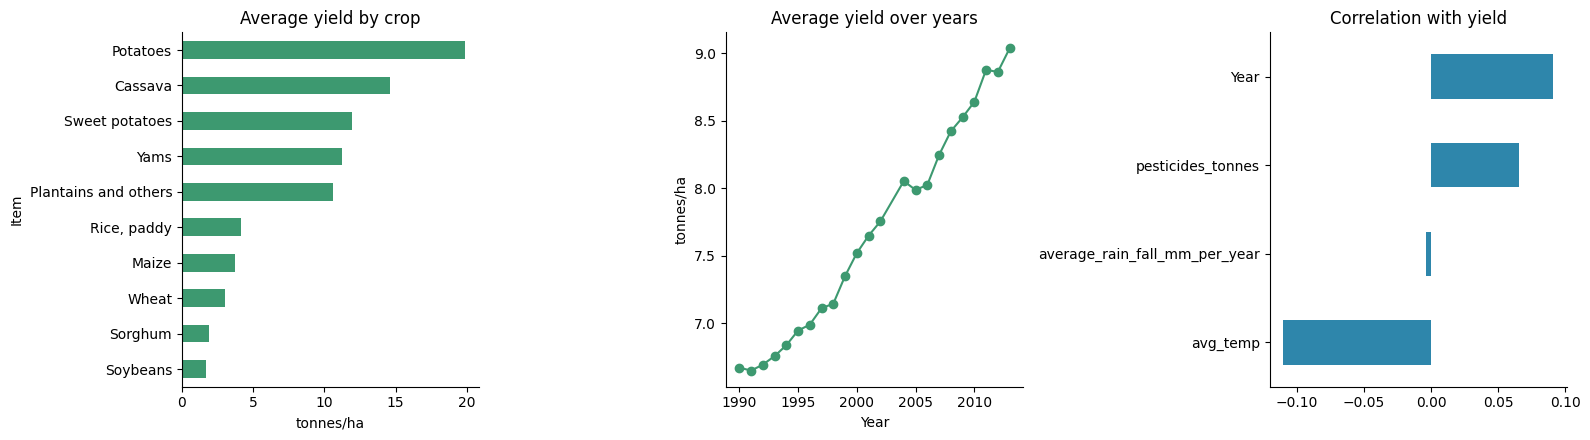

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

df.groupby("Item")["yield_t_ha"].mean().sort_values().plot.barh(ax=ax[0], color="#3D9970")
ax[0].set_title("Average yield by crop"); ax[0].set_xlabel("tonnes/ha")

df.groupby("Year")["yield_t_ha"].mean().plot(ax=ax[1], marker="o", color="#3D9970")
ax[1].set_title("Average yield over years"); ax[1].set_ylabel("tonnes/ha")

num = ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
df[num].corrwith(df["hg/ha_yield"]).sort_values().plot.barh(ax=ax[2], color="#2E86AB")
ax[2].set_title("Correlation with yield")

plt.tight_layout(); plt.show()

---
# STEP 3 – Transformation
**Goal:** convert the data into a form the algorithms can use.

1. **Encoding:** Country and Crop are text → give each a number code.
2. **Train / Test split:** 80% to learn, 20% to test.
3. **Standardisation (z-score):** put every feature on the same scale. This is vital for k-NN because it uses distances.

$$z = \frac{x - \mu}{\sigma}$$

($\mu$ and $\sigma$ are taken from the **training** data only, so the test data stays unseen.)

In [6]:
# 1. Encoding
area_map = {name: i for i, name in enumerate(sorted(df["Area"].unique()))}
crop_map = {name: i for i, name in enumerate(sorted(df["Item"].unique()))}

data = df.copy()
data["Area"] = data["Area"].map(area_map)
data["Item"] = data["Item"].map(crop_map)

features = ["Area", "Item", "Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
feature_names = ["Country", "Crop", "Year", "Rainfall", "Pesticides", "Temperature"]

X = data[features].values.astype(float)
y = data["hg/ha_yield"].values.astype(float)

# 2. Train / test split (80/20)
idx = np.random.permutation(len(X))
cut = int(0.8 * len(X))
train_idx, test_idx = idx[:cut], idx[cut:]
X_train_raw, X_test_raw = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# 3. Standardise using training mean and std
mu, sigma = X_train_raw.mean(axis=0), X_train_raw.std(axis=0)
X_train = (X_train_raw - mu) / sigma
X_test  = (X_test_raw  - mu) / sigma

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (20745, 6)  Test: (5187, 6)


---
# STEP 4 – Data Mining (build the models)
Both models are built **from scratch with maths**.

## 4.1 k-Nearest Neighbours (k-NN) Regression

**Idea:** similar inputs give similar yields. To predict a new point, find the $k$ closest training points and average their yields.

**Step 1 – Euclidean distance** between new point $\mathbf{a}$ and a training point $\mathbf{b}$ with $m$ features:

$$d(\mathbf{a},\mathbf{b}) = \sqrt{\sum_{j=1}^{m}(a_j - b_j)^2}$$

**Step 2 – Prediction:** take the $k$ smallest distances (neighbours $N_k$) and average:

$$\hat{y} = \frac{1}{k}\sum_{i \in N_k} y_i$$

**Choosing k:** we try several $k$ values on a validation set and keep the one with the lowest RMSE.

In [7]:
def distances(X_train, point):
    # Euclidean distance from one point to every training row
    return np.sqrt(np.sum((X_train - point) ** 2, axis=1))

def knn_predict(X_train, y_train, X_new, k):
    preds = []
    for point in X_new:
        d = distances(X_train, point)
        nearest = np.argsort(d)[:k]            # indices of the k smallest distances
        preds.append(y_train[nearest].mean())  # average their yields
    return np.array(preds)

Best k = 1


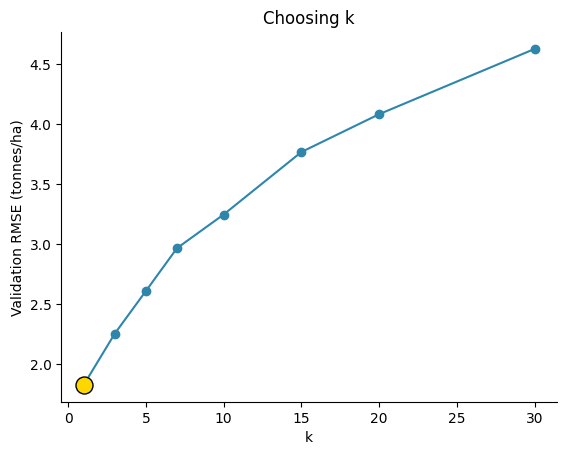

In [8]:
# Choose k using a validation set cut from the TRAINING data
n_sub = int(0.85 * len(X_train))
sub_X, sub_y = X_train[:n_sub], y_train[:n_sub]
val_X, val_y = X_train[n_sub:n_sub + 400], y_train[n_sub:n_sub + 400]

k_values = [1, 3, 5, 7, 10, 15, 20, 30]
sq_err = {k: 0.0 for k in k_values}

for point, actual in zip(val_X, val_y):
    order = np.argsort(distances(sub_X, point))     # sort once, reuse for each k
    for k in k_values:
        sq_err[k] += (actual - sub_y[order[:k]].mean()) ** 2

val_rmse = [np.sqrt(sq_err[k] / len(val_X)) / 10000 for k in k_values]
best_k = k_values[int(np.argmin(val_rmse))]
print("Best k =", best_k)

plt.plot(k_values, val_rmse, marker="o", color="#2E86AB")
plt.scatter([best_k], [min(val_rmse)], s=150, color="gold", edgecolor="k", zorder=3)
plt.xlabel("k"); plt.ylabel("Validation RMSE (tonnes/ha)"); plt.title("Choosing k")
plt.show()

In [9]:
knn_pred = knn_predict(X_train, y_train, X_test, k=best_k)
print("k-NN done with k =", best_k)

k-NN done with k = 1


## 4.2 Random Forest Regression

A Random Forest is many **decision trees** whose predictions are averaged.

### (a) A decision tree
At each node we pick a feature $j$ and a threshold $t$ that splits the data into Left ($x_j \le t$) and Right ($x_j > t$). The best split is the one with the **lowest weighted MSE**:

$$\text{MSE}(S) = \frac{1}{|S|}\sum_{i\in S}(y_i - \bar{y}_S)^2 \qquad\qquad
\text{Cost} = \frac{|L|}{|S|}\text{MSE}(L) + \frac{|R|}{|S|}\text{MSE}(R)$$

We keep splitting until the max depth is reached or the node has too few samples. A **leaf** predicts the mean yield $\bar{y}$ of its samples.

### (b) Making it a *forest*
1. **Bagging (bootstrap):** each tree is trained on a random sample of rows drawn *with replacement*.
2. **Random features:** at every split only a random subset of features is considered (this makes the trees different from each other).
3. **Averaging:** the final prediction is the mean of all $T$ trees:

$$\hat{y} = \frac{1}{T}\sum_{t=1}^{T}\hat{y}_t$$

In [10]:
def mse(y):
    return np.mean((y - y.mean()) ** 2) if len(y) else 0.0

def best_split(X, y, feature_subset):
    best = (np.inf, None, None)                      # (cost, feature, threshold)
    for f in feature_subset:
        col = X[:, f]
        # candidate thresholds = 10th, 20th ... 90th percentiles
        for t in np.unique(np.percentile(col, np.arange(10, 100, 10))):
            left, right = y[col <= t], y[col > t]
            if len(left) == 0 or len(right) == 0:
                continue
            cost = (len(left) * mse(left) + len(right) * mse(right)) / len(y)
            if cost < best[0]:
                best = (cost, f, t)
    return best[1], best[2]

def build_tree(X, y, depth, max_depth, min_samples, max_features):
    # leaf: depth reached, too few samples, or all yields identical
    if depth >= max_depth or len(y) < min_samples or np.all(y == y[0]):
        return y.mean()

    # random subset of features for this split
    subset = np.random.choice(X.shape[1], max_features, replace=False)
    f, t = best_split(X, y, subset)
    if f is None:
        return y.mean()

    mask = X[:, f] <= t
    return {"f": f, "t": t,
            "left":  build_tree(X[mask],  y[mask],  depth + 1, max_depth, min_samples, max_features),
            "right": build_tree(X[~mask], y[~mask], depth + 1, max_depth, min_samples, max_features)}

def predict_tree(node, x):
    while isinstance(node, dict):                    # walk down until a leaf
        node = node["left"] if x[node["f"]] <= node["t"] else node["right"]
    return node

In [11]:
def random_forest(X, y, n_trees=20, max_depth=8, min_samples=10, max_features=3):
    trees = []
    for i in range(n_trees):
        rows = np.random.choice(len(X), len(X), replace=True)       # bootstrap sample
        trees.append(build_tree(X[rows], y[rows], 0, max_depth, min_samples, max_features))
    return trees

def forest_predict(trees, X_new):
    # average the predictions of all trees
    return np.array([np.mean([predict_tree(t, x) for t in trees]) for x in X_new])

np.random.seed(42)
trees = random_forest(X_train, y_train)
rf_pred = forest_predict(trees, X_test)
print("Random Forest done with", len(trees), "trees")

Random Forest done with 20 trees


---
# STEP 5 – Interpretation / Evaluation
**Goal:** measure how good the models are and turn results into knowledge.

With actual values $y_i$, predictions $\hat{y}_i$, mean $\bar{y}$ and $n$ test rows:

$$\text{MAE}=\frac{1}{n}\sum|y_i-\hat{y}_i| \qquad
\text{RMSE}=\sqrt{\frac{1}{n}\sum(y_i-\hat{y}_i)^2} \qquad
R^2 = 1-\frac{\sum(y_i-\hat{y}_i)^2}{\sum(y_i-\bar{y})^2}$$

Lower MAE/RMSE is better. $R^2$ closer to 1 is better.

In [12]:
def evaluate(actual, pred):
    mae  = np.mean(np.abs(actual - pred))
    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    r2   = 1 - np.sum((actual - pred) ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

knn_mae, knn_rmse, knn_r2 = evaluate(y_test, knn_pred)
rf_mae,  rf_rmse,  rf_r2  = evaluate(y_test, rf_pred)

results = pd.DataFrame({
    "Model": ["k-NN", "Random Forest"],
    "MAE (hg/ha)":  [knn_mae, rf_mae],
    "RMSE (hg/ha)": [knn_rmse, rf_rmse],
    "R2":           [knn_r2, rf_r2],
}).round(3)
results

,Model,MAE (hg/ha),RMSE (hg/ha),R2
0,k-NN,4714.411,15354.923,0.967
1,Random Forest,16229.924,26806.752,0.900


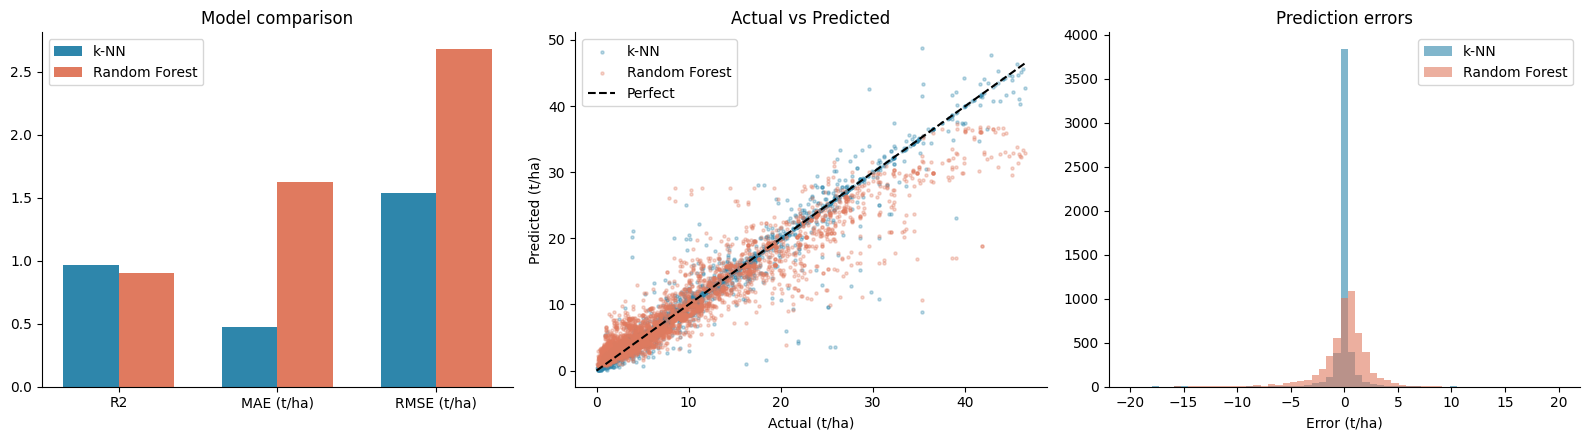

In [13]:
KNN_C, RF_C = "#2E86AB", "#E07A5F"
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. metric comparison
x = np.arange(3); w = 0.35
ax[0].bar(x - w/2, [knn_r2, knn_mae/1e4, knn_rmse/1e4], w, color=KNN_C, label="k-NN")
ax[0].bar(x + w/2, [rf_r2,  rf_mae/1e4,  rf_rmse/1e4],  w, color=RF_C,  label="Random Forest")
ax[0].set_xticks(x); ax[0].set_xticklabels(["R2", "MAE (t/ha)", "RMSE (t/ha)"])
ax[0].set_title("Model comparison"); ax[0].legend()

# 2. actual vs predicted
lim = y_test.max() / 1e4
ax[1].scatter(y_test/1e4, knn_pred/1e4, s=5, alpha=0.3, color=KNN_C, label="k-NN")
ax[1].scatter(y_test/1e4, rf_pred/1e4,  s=5, alpha=0.3, color=RF_C,  label="Random Forest")
ax[1].plot([0, lim], [0, lim], "k--", label="Perfect")
ax[1].set_xlabel("Actual (t/ha)"); ax[1].set_ylabel("Predicted (t/ha)")
ax[1].set_title("Actual vs Predicted"); ax[1].legend()

# 3. error distribution
bins = np.linspace(-20, 20, 60)
ax[2].hist((knn_pred - y_test)/1e4, bins=bins, alpha=0.6, color=KNN_C, label="k-NN")
ax[2].hist((rf_pred  - y_test)/1e4, bins=bins, alpha=0.6, color=RF_C,  label="Random Forest")
ax[2].set_xlabel("Error (t/ha)"); ax[2].set_title("Prediction errors"); ax[2].legend()

plt.tight_layout(); plt.show()

### Which features matter? (Permutation importance)
Shuffle one feature at a time. If the error goes up a lot, the model depended on that feature.

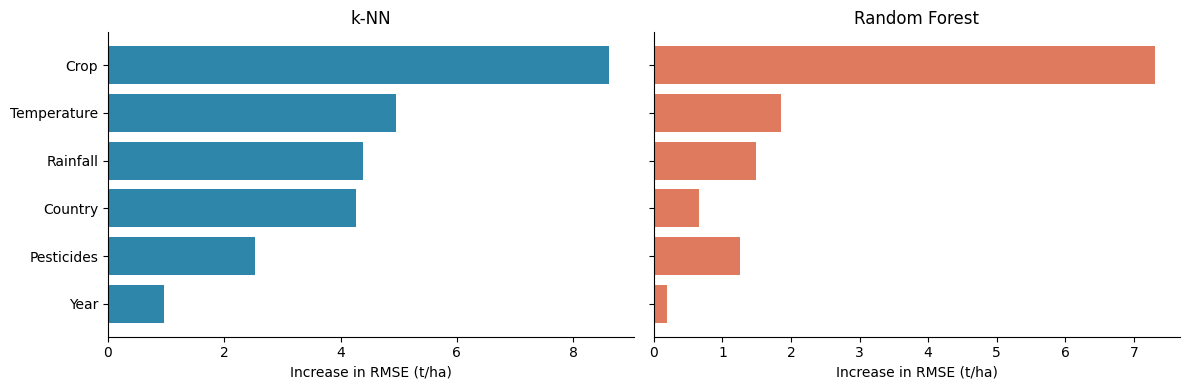

In [14]:
rng = np.random.RandomState(0)
pick = rng.choice(len(X_test), min(300, len(X_test)), replace=False)
Xs, ys = X_test[pick], y_test[pick]

def importance(predict_fn):
    base = np.sqrt(np.mean((ys - predict_fn(Xs)) ** 2))
    out = []
    for j in range(Xs.shape[1]):
        Xp = Xs.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        out.append((np.sqrt(np.mean((ys - predict_fn(Xp)) ** 2)) - base) / 1e4)
    return np.array(out)

knn_imp = importance(lambda A: knn_predict(X_train, y_train, A, best_k))
rf_imp  = importance(lambda A: forest_predict(trees, A))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, imp, name, c in [(ax[0], knn_imp, "k-NN", KNN_C), (ax[1], rf_imp, "Random Forest", RF_C)]:
    o = np.argsort(imp)
    a.barh(np.array(feature_names)[o], imp[o], color=c)
    a.set_title(name); a.set_xlabel("Increase in RMSE (t/ha)")
plt.tight_layout(); plt.show()

In [15]:
winner = "k-NN" if knn_r2 > rf_r2 else "Random Forest"
print("KNOWLEDGE DISCOVERED")
print("-" * 55)
print(f"1. Best model        : {winner} (R2 = {max(knn_r2, rf_r2):.3f})")
print(f"2. k-NN best k       : {best_k}")
print(f"3. Top feature k-NN  : {feature_names[int(np.argmax(knn_imp))]}")
print(f"4. Top feature RF    : {feature_names[int(np.argmax(rf_imp))]}")
print(f"5. Avg error (best)  : {min(knn_mae, rf_mae)/1e4:.2f} tonnes/ha")

KNOWLEDGE DISCOVERED
-------------------------------------------------------
1. Best model        : k-NN (R2 = 0.967)
2. k-NN best k       : 1
3. Top feature k-NN  : Crop
4. Top feature RF    : Crop
5. Avg error (best)  : 0.47 tonnes/ha


---
# Comparison – Yield Dataset Only vs 3 Datasets Together
Does adding the rainfall and pesticides files actually help? We re-run **both models** on different feature sets, using the **same rows, same train/test split and same k**, so the comparison is fair.

- **A. Yield only:** Country, Crop, Year, Temperature
- **B. Yield + Rainfall**
- **C. Yield + Pesticides**
- **D. All 3 datasets** (the main model above)

In [16]:
feature_sets = {
    "A. Yield only":         ["Area", "Item", "Year", "avg_temp"],
    "B. Yield + Rainfall":   ["Area", "Item", "Year", "avg_temp", "average_rain_fall_mm_per_year"],
    "C. Yield + Pesticides": ["Area", "Item", "Year", "avg_temp", "pesticides_tonnes"],
    "D. All 3 datasets":     features,
}

rows = []
for name, cols in feature_sets.items():
    Xall = data[cols].values.astype(float)
    Xtr_raw, Xte_raw = Xall[train_idx], Xall[test_idx]          # same split
    m, sd = Xtr_raw.mean(axis=0), Xtr_raw.std(axis=0)
    Xtr, Xte = (Xtr_raw - m) / sd, (Xte_raw - m) / sd

    k_p = knn_predict(Xtr, y_train, Xte, k=best_k)

    np.random.seed(42)
    f_trees = random_forest(Xtr, y_train, max_features=max(2, len(cols) // 2))
    f_p = forest_predict(f_trees, Xte)

    for model, p in [("k-NN", k_p), ("Random Forest", f_p)]:
        mae, rmse, r2 = evaluate(y_test, p)
        rows.append([name, model, mae / 1e4, rmse / 1e4, r2])
    print("Done:", name)

compare = pd.DataFrame(rows, columns=["Feature set", "Model", "MAE (t/ha)", "RMSE (t/ha)", "R2"])
compare.round(4)

Done: A. Yield only
Done: B. Yield + Rainfall
Done: C. Yield + Pesticides
Done: D. All 3 datasets


,Feature set,Model,MAE (t/ha),RMSE (t/ha),R2
0,A. Yield only,k-NN,1.5135,3.9503,0.7824
1,A. Yield only,Random Forest,2.2896,3.6058,0.8187
2,B. Yield + Rainfall,k-NN,0.5278,1.7779,0.9559
3,B. Yield + Rainfall,Random Forest,2.2061,3.2774,0.8503
4,C. Yield + Pesticides,k-NN,0.9222,2.9033,0.8825
5,C. Yield + Pesticides,Random Forest,2.1887,3.3981,0.8390
6,D. All 3 datasets,k-NN,0.4714,1.5355,0.9671
7,D. All 3 datasets,Random Forest,1.6230,2.6807,0.8998


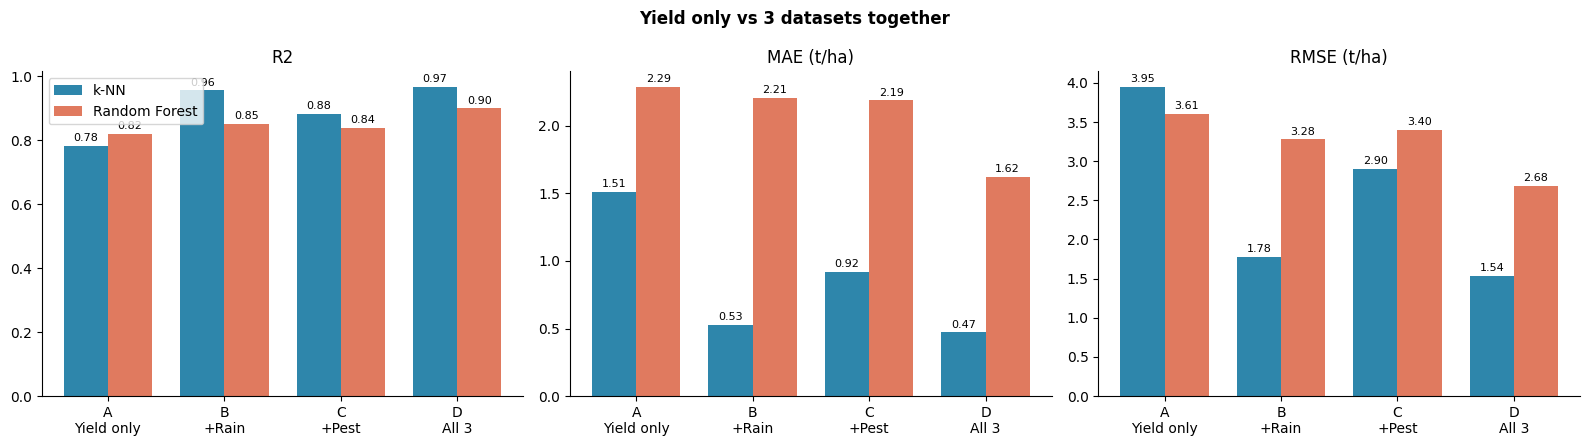

COMPARISON CONCLUSION
1. Best: k-NN with 'D. All 3 datasets' (R2 = 0.967)
2. Yield only best R2 = 0.819  vs  all 3 datasets best R2 = 0.967
3. Adding rainfall and pesticides IMPROVED the predictions.


In [17]:
sets = list(feature_sets)
x = np.arange(len(sets)); w = 0.38

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric in zip(ax, ["R2", "MAE (t/ha)", "RMSE (t/ha)"]):
    for off, model, c in [(-w/2, "k-NN", KNN_C), (w/2, "Random Forest", RF_C)]:
        vals = [compare[(compare["Feature set"] == s) & (compare["Model"] == model)][metric].iloc[0] for s in sets]
        b = a.bar(x + off, vals, w, color=c, label=model)
        a.bar_label(b, fmt="%.2f", fontsize=8, padding=2)
    a.set_xticks(x); a.set_xticklabels(["A\nYield only", "B\n+Rain", "C\n+Pest", "D\nAll 3"])
    a.set_title(metric)
ax[0].legend()
plt.suptitle("Yield only vs 3 datasets together", fontweight="bold")
plt.tight_layout(); plt.show()

best = compare.loc[compare["R2"].idxmax()]
a_r2 = compare[compare["Feature set"] == sets[0]]["R2"].max()
d_r2 = compare[compare["Feature set"] == sets[3]]["R2"].max()
print("COMPARISON CONCLUSION")
print(f"1. Best: {best['Model']} with '{best['Feature set']}' (R2 = {best['R2']:.3f})")
print(f"2. Yield only best R2 = {a_r2:.3f}  vs  all 3 datasets best R2 = {d_r2:.3f}")
print("3. Adding rainfall and pesticides", "IMPROVED" if d_r2 > a_r2 else "did NOT improve", "the predictions.")

---
# Using the Knowledge – Predict a New Yield (user input)
Run the cell and type your own values. Each answer is checked against the range seen in the training data.

CROP YIELD PREDICTION

Country (example: India): USA
Not found. Valid options are:
Albania, Algeria, Angola, Argentina, Armenia, Australia, Austria, Azerbaijan, Bahamas, Bahrain, Bangladesh, Belarus, Belgium, Botswana, Brazil, Bulgaria, Burkina Faso, Burundi, Cameroon, Canada, Central African Republic, Chile, Colombia, Croatia, Denmark, Dominican Republic, Ecuador, Egypt, El Salvador, Eritrea, Estonia, Finland, France, Germany, Ghana, Greece, Guatemala, Guinea, Guyana, Haiti, Honduras, Hungary, India, Indonesia, Iraq, Ireland, Italy, Jamaica, Japan, Kazakhstan, Kenya, Latvia, Lebanon, Lesotho, Libya, Lithuania, Madagascar, Malawi, Malaysia, Mali, Mauritania, Mauritius, Mexico, Montenegro, Morocco, Mozambique, Namibia, Nepal, Netherlands, New Zealand, Nicaragua, Niger, Norway, Pakistan, Papua New Guinea, Peru, Poland, Portugal, Qatar, Romania, Rwanda, Saudi Arabia, Senegal, Slovenia, South Africa, Spain, Sri Lanka, Sudan, Suriname, Sweden, Switzerland, Tajikistan, Thailand, Tunisia, Tur

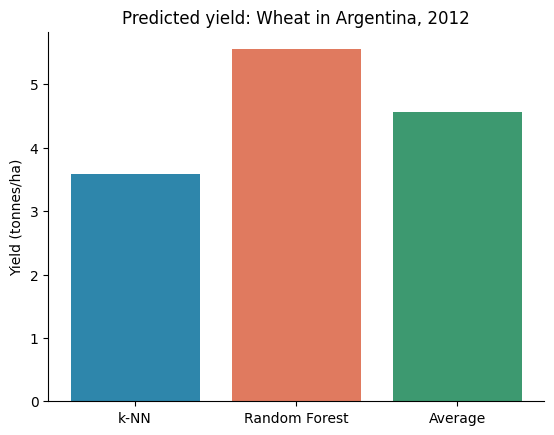

In [18]:
year_min, year_max = int(df["Year"].min()), int(df["Year"].max())
rain_min, rain_max = df["average_rain_fall_mm_per_year"].min(), df["average_rain_fall_mm_per_year"].max()
pest_min, pest_max = df["pesticides_tonnes"].min(), df["pesticides_tonnes"].max()
temp_min, temp_max = df["avg_temp"].min(), df["avg_temp"].max()

def ask_name(question, valid_names):
    # keep asking until the name matches (capital letters do not matter)
    while True:
        text = input(question).strip().lower()
        for name in valid_names:
            if name.lower() == text:
                return name
        print("Not found. Valid options are:")
        print(", ".join(sorted(valid_names)))

def ask_number(question, low, high):
    # keep asking until a number inside the range is entered
    while True:
        try:
            value = float(input(question))
        except ValueError:
            print("Please enter a number.")
            continue
        if low <= value <= high:
            return value
        print(f"Value must be between {low:g} and {high:g}.")

print("CROP YIELD PREDICTION\n")
area        = ask_name("Country (example: India): ", area_map)
crop        = ask_name("Crop (example: Maize): ", crop_map)
year        = int(ask_number(f"Year ({year_min} to {year_max}): ", year_min, year_max))
rainfall    = ask_number(f"Rainfall in mm per year ({rain_min:,.0f} to {rain_max:,.0f}): ", rain_min, rain_max)
pesticides  = ask_number(f"Pesticides in tonnes ({pest_min:,.0f} to {pest_max:,.0f}): ", pest_min, pest_max)
temperature = ask_number(f"Average temperature in C ({temp_min:.0f} to {temp_max:.0f}): ", temp_min, temp_max)

new = np.array([[area_map[area], crop_map[crop], year, rainfall, pesticides, temperature]], dtype=float)
new = (new - mu) / sigma                      # same scaling as training

knn_t = knn_predict(X_train, y_train, new, best_k)[0] / 1e4
rf_t  = forest_predict(trees, new)[0] / 1e4
avg_t = (knn_t + rf_t) / 2

print("\n" + "=" * 40)
print(f"{crop} in {area}, {year}")
print("=" * 40)
print(f"k-NN            : {knn_t:.2f} tonnes/ha")
print(f"Random Forest   : {rf_t:.2f} tonnes/ha")
print(f"Average of both : {avg_t:.2f} tonnes/ha")
print(f"Difference      : {abs(knn_t - rf_t):.2f} tonnes/ha")

plt.bar(["k-NN", "Random Forest", "Average"], [knn_t, rf_t, avg_t], color=[KNN_C, RF_C, "#3D9970"])
plt.ylabel("Yield (tonnes/ha)"); plt.title(f"Predicted yield: {crop} in {area}, {year}")
plt.show()